# 03 · Risk model: abandonment risk per block (run on LinuxONE)

Model chosen in notebook 02: **XGBoost regression on % vacant homes, without the crime feature** (crime added no accuracy; it is used for alerts in notebook 04).

1. Honest risk scores for every block with out-of-fold predictions (each neighborhood scored by a model that never saw it).
2. Risk levels: high = top 10%, medium = next 20%, low = the rest.
3. Three reasons per block from XGBoost's per-prediction contributions.
4. A final model trained on all blocks, saved for notebook 04 and for scoring new requests.

Outputs: `results/block_risk.csv`, `results/xgb_risk_model.json`.

In [1]:
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

HIGH = 25  # % vacant that counts as a high-vacancy block
PARAMS = dict(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
              colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)  # same as notebook 02
print(platform.machine(), "| Python", platform.python_version(), "| XGBoost", xgb.__version__)

d = pd.read_csv("../data/features.csv")
ID_COLS = ["CVEGEO", "AGEB_KEY", "TVIVPAR", "vacant_masked", "target_pct_vacant", "lon", "lat"]
FEATURES = [c for c in d.columns if c not in ID_COLS + ["crimes_500m", "crimes_500m_pct"]]
X, y = d[FEATURES], d.target_pct_vacant.to_numpy()
high = (y >= HIGH).astype(int)
print(len(d), "blocks |", len(FEATURES), "features")

s390x | Python 3.12.15 | XGBoost 3.4.1
16452 blocks | 25 features


## 1. Out-of-fold risk scores
Grouped by neighborhood (AGEB), like notebook 02, so every published score comes from a model that never saw that neighborhood.

In [2]:
oof = np.zeros(len(d))
for tr, te in GroupKFold(5).split(X, y, d.AGEB_KEY):
    m = xgb.XGBRegressor(**PARAMS).fit(X.iloc[tr], y[tr])
    oof[te] = m.predict(X.iloc[te])
d["risk_score"] = oof
print("AUC (>= 25% vacant):", round(roc_auc_score(high, oof), 3))

AUC (>= 25% vacant): 0.847


## 2. Risk levels

In [3]:
cut_high, cut_med = np.quantile(oof, [0.90, 0.70])
d["risk_level"] = np.select([oof >= cut_high, oof >= cut_med], ["high", "medium"], "low")

levels = d.groupby("risk_level").agg(
    blocks=("CVEGEO", "size"),
    actual_high_vacancy=("target_pct_vacant", lambda s: (s >= HIGH).mean()),
    median_pct_vacant=("target_pct_vacant", "median"),
    vacant_homes=("TVIVPAR", lambda s: (s * d.loc[s.index, "target_pct_vacant"] / 100).sum()),
).reindex(["high", "medium", "low"])
levels["share_of_vacant_homes"] = levels.vacant_homes / levels.vacant_homes.sum()
print(f"score cut-offs: high >= {cut_high:.1f}, medium >= {cut_med:.1f} | base rate {high.mean():.3f}")
levels.round(3)

score cut-offs: high >= 20.0, medium >= 12.6 | base rate 0.113


,blocks,actual_high_vacancy,median_pct_vacant,vacant_homes,share_of_vacant_homes
risk_level,,,,,
high,1646,0.494,23.810,8544.0,0.172
medium,3290,0.194,13.043,11126.0,0.224
low,11516,0.036,7.317,29978.5,0.604


## 3. Final model and reasons per block
Trained on all blocks. `pred_contribs` splits each prediction into one contribution per feature (in % vacant points); the three largest positive ones are the block's reasons.

In [4]:
model = xgb.XGBRegressor(**PARAMS).fit(X, y)
contrib = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)[:, :-1]  # last column is the bias
contrib = pd.DataFrame(contrib, columns=FEATURES, index=d.index)

LABELS = {
    "km_center": "km to city center", "km_maquila": "km to nearest maquila", "maquilas_3km": "maquilas within 3 km",
    "km_brt": "km to BRT station", "km_health": "km to health unit", "km_school": "km to primary school",
    "year_urbanized": "year urbanized", "property_value": "cadastral value", "dwellings_per_ha": "homes per hectare",
    "area_ha": "block area (ha)", "avg_occupants": "occupants per home", "schooling_years": "avg schooling years",
    "pct_POB0_14": "% children 0-14", "pct_POB65_MAS": "% adults 65+", "pct_PDER_SS": "% with health insurance",
    "pct_PEA": "% economically active", "pct_VPH_INTER": "% homes with internet", "pct_VPH_AUTOM": "% homes with car",
    "pct_VPH_PISOTI": "% homes with dirt floor", "pct_VPH_C_ELEC": "% homes with electricity",
    "pct_VPH_AGUADV": "% homes with piped water", "pct_VPH_DRENAJ": "% homes with drainage",
    "pct_VPH_PC": "% homes with computer", "pct_VPH_CEL": "% homes with cell phone", "pct_VPH_1CUART": "% one-room homes",
}
city_median = X.median()

def reasons(i, n=3):
    top = contrib.loc[i].sort_values(ascending=False).head(n)
    out = []
    for f, c in top.items():
        if c <= 0:
            continue
        v = X.at[i, f]
        # INEGI does not publish some values for small blocks; the gap itself carries signal
        shown = "not reported" if pd.isna(v) else f"{v:.1f}"
        out.append(f"{LABELS.get(f, f)}: {shown} (city median {city_median[f]:.1f}, +{c:.1f} pts)")
    return out

r = [reasons(i) for i in d.index]
for k in range(3):
    d[f"reason_{k + 1}"] = [x[k] if len(x) > k else "" for x in r]
d.loc[d.risk_level == "high"].nlargest(5, "risk_score")[["CVEGEO", "target_pct_vacant", "risk_score", "reason_1", "reason_2", "reason_3"]]

,CVEGEO,target_pct_vacant,risk_score,reason_1,reason_2,reason_3
0,0803700018286011,46.153846,71.727249,"km to city center: 25.7 (city median 9.6, +13....",% homes with car: not reported (city median 65...,"% homes with internet: 0.0 (city median 64.3, ..."
12828,0803700018286022,41.666667,67.642242,"km to city center: 25.3 (city median 9.6, +14....","km to BRT station: 7.5 (city median 1.7, +6.7 ...",% homes with car: not reported (city median 65...
8613,0803700010806016,54.545455,56.911476,"km to city center: 1.3 (city median 9.6, +15.9...",% homes with car: not reported (city median 65...,% homes with internet: not reported (city medi...
16158,080370001756A105,68.750000,56.546417,"year urbanized: 2019.0 (city median 1990.0, +3...",% with health insurance: 100.0 (city median 81...,"avg schooling years: 15.4 (city median 9.4, +3..."
16331,0803700017589123,93.617021,55.536129,"year urbanized: 2020.0 (city median 1990.0, +2...","avg schooling years: 14.0 (city median 9.4, +7...","block area (ha): 2.0 (city median 0.5, +7.2 pts)"


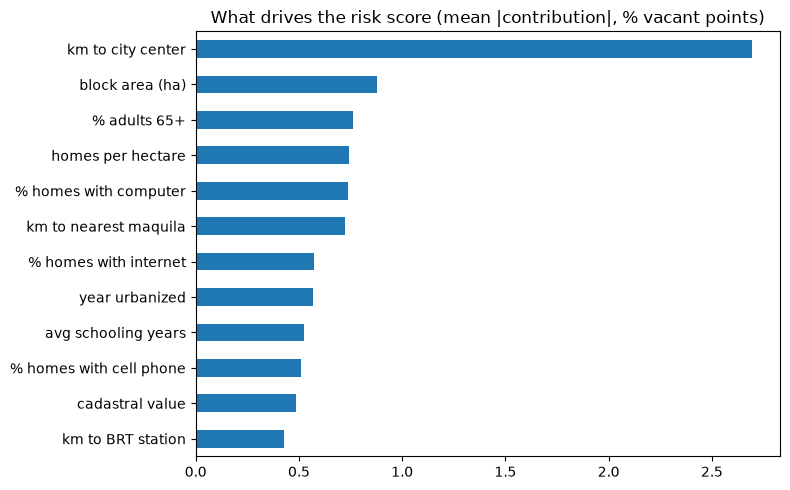

In [5]:
imp = contrib.abs().mean().sort_values().tail(12).rename(index=LABELS)
imp.plot.barh(figsize=(8, 5), title="What drives the risk score (mean |contribution|, % vacant points)")
plt.tight_layout()

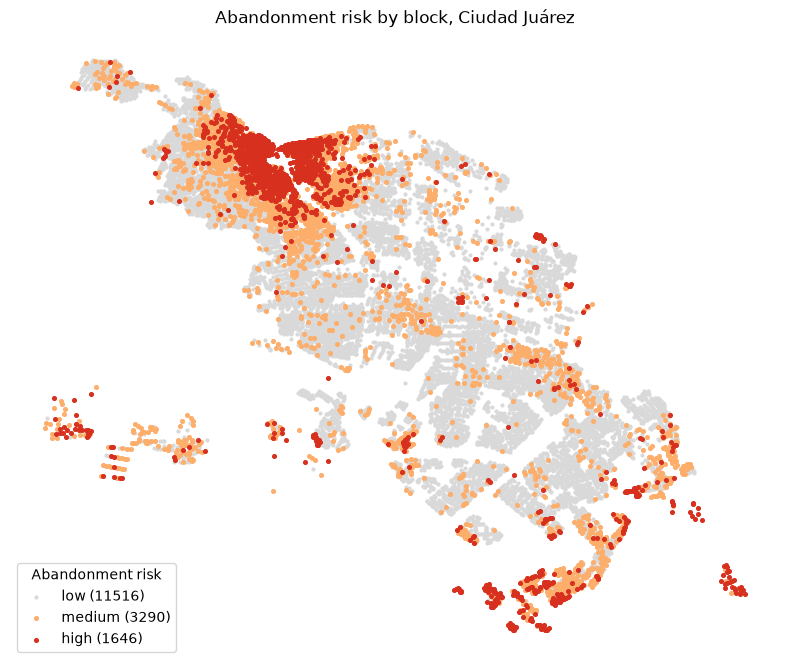

In [6]:
colors = {"low": "#d9d9d9", "medium": "#fdae6b", "high": "#d7301f"}
fig, ax = plt.subplots(figsize=(8, 7))
for lvl in ["low", "medium", "high"]:
    s = d[d.risk_level == lvl]
    ax.scatter(s.lon, s.lat, s=4 if lvl == "low" else 7, c=colors[lvl], label=f"{lvl} ({len(s)})")
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend(title="Abandonment risk", loc="lower left")
ax.set_title("Abandonment risk by block, Ciudad Juárez")
plt.tight_layout()

## 4. Scoring speed on this machine
One full re-score of the city, and one single-block request (like a credit check).

In [7]:
t0 = time.perf_counter(); model.predict(X); full = time.perf_counter() - t0
one = X.iloc[[0]]
t0 = time.perf_counter()
for _ in range(200):
    model.predict(one)
single = (time.perf_counter() - t0) / 200
print(f"{platform.machine()}: all {len(X)} blocks in {full * 1000:.1f} ms | one block in {single * 1000:.2f} ms")

s390x: all 16452 blocks in 84.5 ms | one block in 1.43 ms


## 5. Save outputs for notebook 04

In [8]:
cols = ["CVEGEO", "AGEB_KEY", "lon", "lat", "TVIVPAR", "target_pct_vacant", "risk_score", "risk_level",
        "reason_1", "reason_2", "reason_3"]
d[cols].round({"risk_score": 2, "target_pct_vacant": 2}).to_csv("../results/block_risk.csv", index=False)
model.save_model("../results/xgb_risk_model.json")
print("saved results/block_risk.csv and results/xgb_risk_model.json")

saved results/block_risk.csv and results/xgb_risk_model.json
